# 六类动物识别：产生式系统

本 Notebook 实现并评价基于事实、IF–THEN 规则和正向链的六类动物识别系统，目标类别为猫、狗、鸡、马、牛、羊。

> **规则来源说明**：Animals-10 只提供图片及动物类别标签，不包含“有毛发”“反刍”“会喵叫”等属性标注。本项目的规则来自常识性动物知识和经典动物识别专家系统的规则结构，并针对六个目标类别人工整理；它们不是从 Animals-10 训练、统计或自动生成的。Animals-10 在本方法中只用于统一最终类别名称。

产生式系统没有可学习参数，不执行损失计算、反向传播或 epoch 训练。它的开发过程是人工构建知识库，再通过标准案例、冲突案例和符号压力测试验证规则。

In [1]:
from pathlib import Path
import sys

# 同时兼容从项目根目录和 notebooks 目录启动 notebook。
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'src').exists() else cwd.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError(f'无法定位项目根目录，当前目录为 {cwd}')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print('项目根目录:', PROJECT_ROOT)
print('Python:', sys.version.split()[0])
print('解释器:', sys.executable)

项目根目录: D:\AI\animal-classification
Python: 3.14.8
解释器: D:\AI\animal-classification\.venv\Scripts\python.exe


## 运行产生式系统的六类标准案例

In [2]:
import pandas as pd
from src.production_system import ANIMALS, EXAMPLES, create_engine

engine = create_engine()
results = []
for expected in ANIMALS:
    result = engine.infer(EXAMPLES[expected])
    results.append({'预期类别': expected, '识别结果': result.animal, '状态': result.status, '触发规则数': len(result.fired_rules), '是否正确': result.animal == expected})

result_table = pd.DataFrame(results)
assert result_table['是否正确'].all(), '存在未正确识别的标准案例'
result_table

,预期类别,识别结果,状态,触发规则数,是否正确
0,猫,猫,recognized,3,True
1,狗,狗,recognized,3,True
2,鸡,鸡,recognized,2,True
3,马,马,recognized,3,True
4,牛,牛,recognized,4,True
5,羊,羊,recognized,4,True


## 查看一条完整推理轨迹

In [3]:
example_name = '猫'
result = engine.infer(EXAMPLES[example_name])
print('初始事实:', '、'.join(sorted(result.initial_facts)))
for step, fired in enumerate(result.fired_rules, start=1):
    rule = fired.rule
    premises = ' AND '.join(sorted(rule.premises))
    print(f'{step}. {rule.rule_id}: IF {premises} THEN {rule.conclusion}')
    print('  说明:', rule.explanation)
print('最终识别结果:', result.animal)

初始事实: 会喵叫、吃肉、家养、有毛发
1. R01: IF 有毛发 THEN 哺乳动物
  说明: 有毛发的动物是哺乳动物
2. R05: IF 吃肉 THEN 食肉动物
  说明: 会摄食肉类的动物属于食肉动物
3. R09: IF 会喵叫 AND 哺乳动物 AND 家养 AND 食肉动物 THEN 猫
  说明: 家养且会喵叫的食肉哺乳动物是猫
最终识别结果: 猫


## 检查信息不足和规则冲突

In [4]:
incomplete = engine.infer({'有毛发', '家养'})
conflicting = engine.infer({'有毛发', '吃肉', '家养', '会喵叫', '会汪叫'})

print('信息不足案例:', incomplete.status, incomplete.candidates)
print('冲突案例:', conflicting.status, conflicting.candidates)
assert incomplete.status == 'unknown'
assert conflicting.status == 'ambiguous'

信息不足案例: unknown ()
冲突案例: ambiguous ('狗', '猫')


## 运行项目自动测试

In [5]:
import unittest

suite = unittest.defaultTestLoader.discover(str(PROJECT_ROOT / 'tests'))
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), '自动测试没有全部通过'

test_metadata_dataset_and_split_validation (test_cnn.CnnComponentTests.test_metadata_dataset_and_split_validation) ... 

ok


test_model_output_and_freezing (test_cnn.CnnComponentTests.test_model_output_and_freezing) ... 

ok


test_all_reference_cases (test_production_system.ProductionSystemTests.test_all_reference_cases) ... 

...

test_incomplete_facts_are_unknown (test_production_system.ProductionSystemTests.test_incomplete_facts_are_unknown) ... 

ok


test_repeated_facts_do_not_repeat_rules (test_production_system.ProductionSystemTests.test_repeated_facts_do_not_repeat_rules) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.254s

OK


## 产生式方法的量化评价

产生式系统不通过数据迭代训练，因此没有可绘制的 loss/accuracy 训练曲线。本节改用一个**类别均衡的符号压力测试集**评价其推理性能：对每类的标准事实集合分别进行原样测试、逐项删除一个特征、逐项加入一个其他特征，共得到 132 条样本（每类 22 条）。

除常规的 Accuracy、Macro Precision/Recall/F1 外，还报告：

- **Coverage（覆盖率）**：系统给出唯一类别的样本比例；
- **Selective accuracy（选择性准确率）**：仅在系统给出唯一类别时计算正确率；
- **Unknown/Ambiguous rate**：信息不足和规则冲突的比例。

`unknown` 和 `ambiguous` 都按“拒识”计入总体错误，避免系统通过不作答获得虚高分数。由于这里的输入是人工定义的符号事实，而 CNN 的输入是图像，本节结果用于分析规则系统和统一图表格式，**不能当作与 CNN 图像测试集严格同分布的直接对照**。

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from src.production_system import FEATURES

REJECT_LABEL = '拒识'
all_observable_features = set(FEATURES)
benchmark_cases = []

for expected in ANIMALS:
    reference_facts = set(EXAMPLES[expected])
    benchmark_cases.append({
        '真实类别': expected,
        '场景': '标准样例',
        '变动特征': '无',
        '输入事实': frozenset(reference_facts),
    })
    for removed in sorted(reference_facts):
        benchmark_cases.append({
            '真实类别': expected,
            '场景': '缺失1项特征',
            '变动特征': removed,
            '输入事实': frozenset(reference_facts - {removed}),
        })
    for added in sorted(all_observable_features - reference_facts):
        benchmark_cases.append({
            '真实类别': expected,
            '场景': '增加1项干扰特征',
            '变动特征': added,
            '输入事实': frozenset(reference_facts | {added}),
        })

prediction_rows = []
for case in benchmark_cases:
    inference = engine.infer(case['输入事实'])
    prediction_rows.append({
        **case,
        '预测类别': inference.animal if inference.status == 'recognized' else REJECT_LABEL,
        '推理状态': inference.status,
        '是否正确': inference.animal == case['真实类别'],
        '是否作答': inference.status == 'recognized',
    })

production_predictions = pd.DataFrame(prediction_rows)
assert len(production_predictions) == len(ANIMALS) * (len(FEATURES) + 1) == 132
assert production_predictions.groupby('真实类别').size().nunique() == 1

print(f'压力测试样本数: {len(production_predictions)}（每类 {len(FEATURES) + 1} 条）')
pd.crosstab(production_predictions['场景'], production_predictions['推理状态'])

压力测试样本数: 132（每类 22 条）


推理状态,ambiguous,recognized,unknown
场景,,,
增加1项干扰特征,3,93,0
标准样例,0,6,0
缺失1项特征,0,4,26


In [7]:
def metric_row(frame):
    y_true = frame['真实类别']
    y_pred = frame['预测类别']
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(ANIMALS), average='macro', zero_division=0
    )
    answered = frame['是否作答']
    return {
        '样本数': len(frame),
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro Precision': precision_macro,
        'Macro Recall': recall_macro,
        'Macro F1': f1_macro,
        'Coverage': answered.mean(),
        'Selective accuracy': frame.loc[answered, '是否正确'].mean() if answered.any() else np.nan,
        'Unknown rate': (frame['推理状态'] == 'unknown').mean(),
        'Ambiguous rate': (frame['推理状态'] == 'ambiguous').mean(),
    }

scenario_order = ['标准样例', '缺失1项特征', '增加1项干扰特征']
production_summary = pd.DataFrame(
    {'总体': metric_row(production_predictions), **{
        scenario: metric_row(production_predictions[production_predictions['场景'] == scenario])
        for scenario in scenario_order
    }}
).T
production_summary.index.name = '测试范围'

p, r, f1, support = precision_recall_fscore_support(
    production_predictions['真实类别'],
    production_predictions['预测类别'],
    labels=list(ANIMALS),
    zero_division=0,
)
production_per_class = pd.DataFrame({
    'Precision': p, 'Recall': r, 'F1': f1, 'Support': support
}, index=ANIMALS)
production_per_class.index.name = '类别'

print('总体与分场景指标（数值越高越好；Unknown/Ambiguous rate 越低越好）')
display(production_summary.style.format('{:.3f}', subset=production_summary.columns[1:]))
print('按类别指标')
display(production_per_class.style.format('{:.3f}', subset=['Precision', 'Recall', 'F1']))

总体与分场景指标（数值越高越好；Unknown/Ambiguous rate 越低越好）


,样本数,Accuracy,Macro Precision,Macro Recall,Macro F1,Coverage,Selective accuracy,Unknown rate,Ambiguous rate
测试范围,,,,,,,,,
总体,132.000000,0.780,1.000,0.780,0.875,0.780,1.000,0.197,0.023
标准样例,6.000000,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000
缺失1项特征,30.000000,0.133,0.167,0.111,0.133,0.133,1.000,0.867,0.000
增加1项干扰特征,96.000000,0.969,1.000,0.969,0.984,0.969,1.000,0.000,0.031


按类别指标


,Precision,Recall,F1,Support
类别,,,,
猫,1.000,0.773,0.872,22
狗,1.000,0.773,0.872,22
鸡,1.000,0.909,0.952,22
马,1.000,0.773,0.872,22
牛,1.000,0.682,0.811,22
羊,1.000,0.773,0.872,22


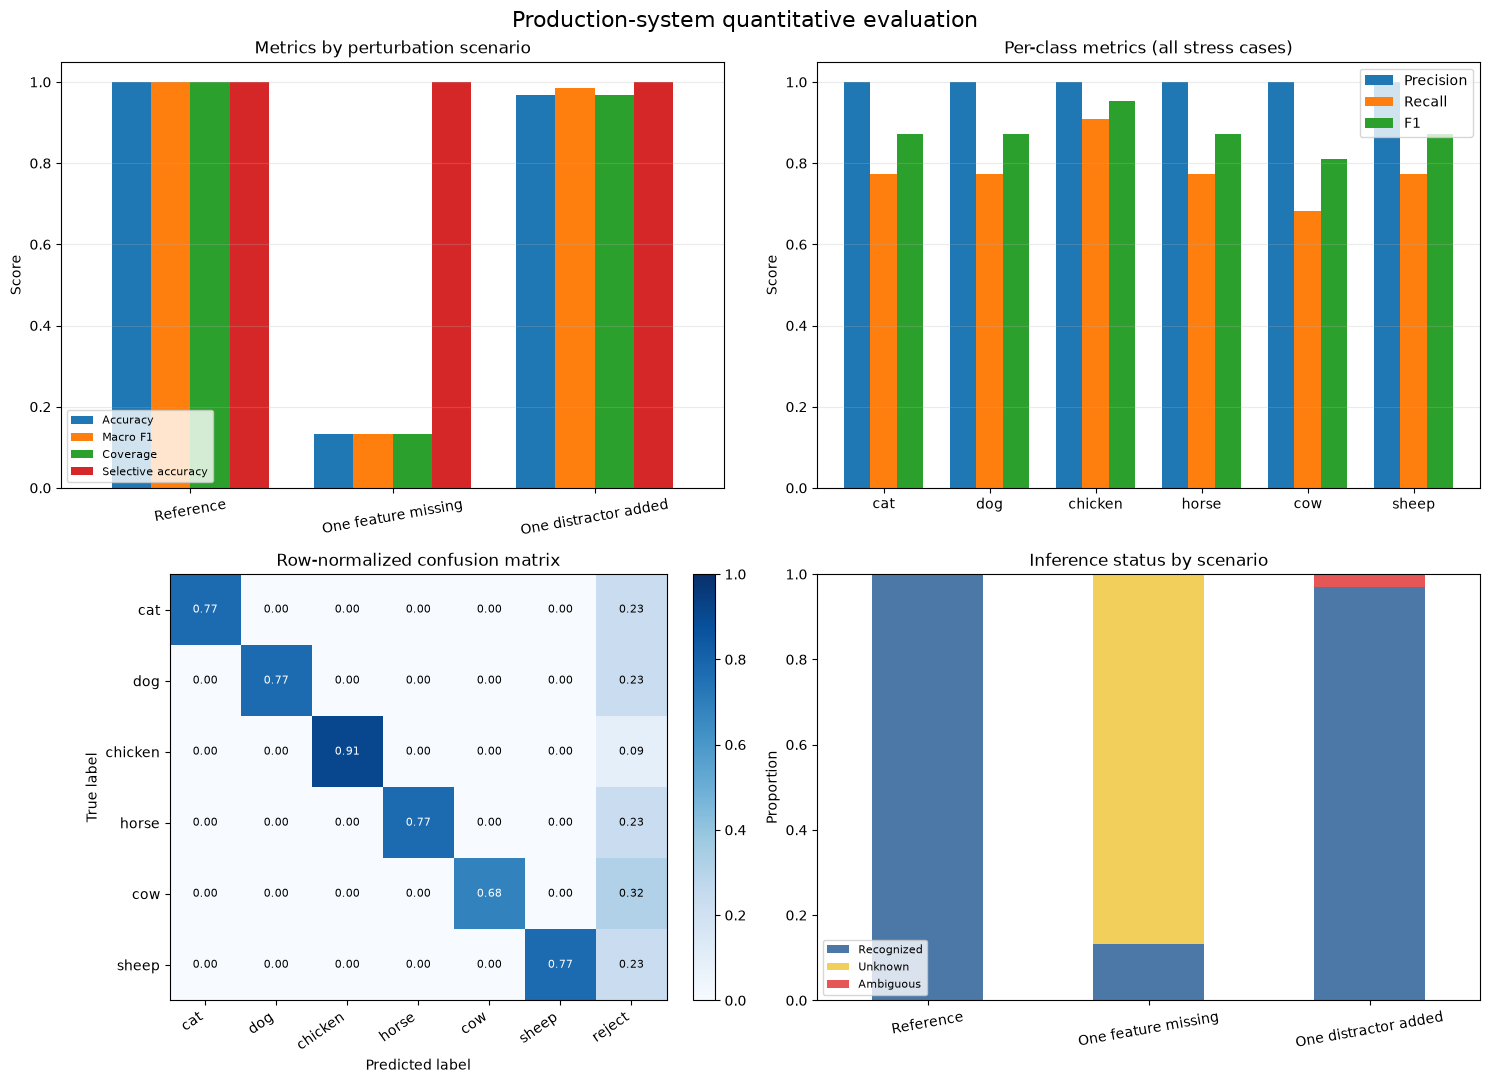

评价结果已导出到: D:\AI\animal-classification\outputs\production_system


In [8]:
# 使用英文图中文字，避免不同操作系统缺少中文字体时出现方框。
animal_en = {'猫': 'cat', '狗': 'dog', '鸡': 'chicken', '马': 'horse', '牛': 'cow', '羊': 'sheep'}
scenario_en = {
    '标准样例': 'Reference',
    '缺失1项特征': 'One feature missing',
    '增加1项干扰特征': 'One distractor added',
}
status_en = {'recognized': 'Recognized', 'unknown': 'Unknown', 'ambiguous': 'Ambiguous'}

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (1) 分场景综合指标；跨方法汇总图见 CNN 实验 Notebook。
scenario_metrics = production_summary.loc[scenario_order, ['Accuracy', 'Macro F1', 'Coverage', 'Selective accuracy']]
scenario_metrics.index = [scenario_en[item] for item in scenario_metrics.index]
scenario_metrics.plot(kind='bar', ylim=(0, 1.05), ax=axes[0, 0], rot=10, width=0.78)
axes[0, 0].set_title('Metrics by perturbation scenario')
axes[0, 0].set_ylabel('Score')
axes[0, 0].legend(loc='lower left', fontsize=8)
axes[0, 0].grid(axis='y', alpha=0.25)

# (2) 每类 Precision / Recall / F1。
per_class_plot = production_per_class[['Precision', 'Recall', 'F1']].copy()
per_class_plot.index = [animal_en[item] for item in per_class_plot.index]
per_class_plot.plot(kind='bar', ylim=(0, 1.05), ax=axes[0, 1], rot=0, width=0.75)
axes[0, 1].set_title('Per-class metrics (all stress cases)')
axes[0, 1].set_ylabel('Score')
axes[0, 1].grid(axis='y', alpha=0.25)

# (3) 按真实类别归一化的混淆矩阵；最后一列明确显示拒识。
matrix_labels = list(ANIMALS) + [REJECT_LABEL]
cm_counts = confusion_matrix(
    production_predictions['真实类别'],
    production_predictions['预测类别'],
    labels=matrix_labels,
)[:len(ANIMALS), :]
cm_norm = cm_counts / cm_counts.sum(axis=1, keepdims=True)
image = axes[1, 0].imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for row in range(cm_norm.shape[0]):
    for col in range(cm_norm.shape[1]):
        value = cm_norm[row, col]
        axes[1, 0].text(col, row, f'{value:.2f}', ha='center', va='center',
                        color='white' if value > 0.5 else 'black', fontsize=8)
axes[1, 0].set_xticks(range(len(matrix_labels)), [animal_en.get(x, 'reject') for x in matrix_labels], rotation=35, ha='right')
axes[1, 0].set_yticks(range(len(ANIMALS)), [animal_en[x] for x in ANIMALS])
axes[1, 0].set_xlabel('Predicted label')
axes[1, 0].set_ylabel('True label')
axes[1, 0].set_title('Row-normalized confusion matrix')
fig.colorbar(image, ax=axes[1, 0], fraction=0.046, pad=0.04)

# (4) 各场景的推理状态分布，显示拒识来自信息不足还是规则冲突。
status_rates = pd.crosstab(
    production_predictions['场景'], production_predictions['推理状态'], normalize='index'
).reindex(index=scenario_order, columns=['recognized', 'unknown', 'ambiguous'], fill_value=0)
status_rates.index = [scenario_en[item] for item in status_rates.index]
status_rates.columns = [status_en[item] for item in status_rates.columns]
status_rates.plot(kind='bar', stacked=True, ylim=(0, 1), ax=axes[1, 1], rot=10,
                  color=['#4C78A8', '#F2CF5B', '#E45756'])
axes[1, 1].set_title('Inference status by scenario')
axes[1, 1].set_ylabel('Proportion')
axes[1, 1].legend(loc='lower left', fontsize=8)

fig.suptitle('Production-system quantitative evaluation', fontsize=16)
fig.tight_layout()

output_dir = PROJECT_ROOT / 'outputs' / 'production_system'
output_dir.mkdir(parents=True, exist_ok=True)
figure_path = output_dir / 'evaluation_dashboard.png'
fig.savefig(figure_path, dpi=200, bbox_inches='tight')
production_summary.to_csv(output_dir / 'summary_metrics.csv', encoding='utf-8-sig')
production_per_class.to_csv(output_dir / 'per_class_metrics.csv', encoding='utf-8-sig')
production_predictions.drop(columns='输入事实').to_csv(
    output_dir / 'predictions.csv', index=False, encoding='utf-8-sig'
)
plt.show()
print('评价结果已导出到:', output_dir)

### 与 CNN 的统一比较约定

已完成的 CNN 在固定且从未参与训练/调参的 `test` 图像集上报告同名的 **Accuracy、Macro Precision、Macro Recall、Macro F1**，并输出按类指标、行归一化混淆矩阵及 train/validation 学习曲线。Macro 指标对六个类别等权，更适合当前类别不均衡的数据。CNN 的 softmax 概率不适用于当前只输出离散结论/拒识的规则系统，因此不把概率曲线作为主比较项。

最终报告应把两套方法的输入差异写清楚：规则系统成绩来自上述符号压力测试，CNN 成绩来自真实图像测试集。因此它们适合比较可解释性、拒识行为、鲁棒性和各自任务内的分类表现，不应把两个 Accuracy 简单解释为同一测试集上的胜负。

图表与指标选择参考：

- [scikit-learn：分类模型评价指标](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn：Classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- [scikit-learn：多分类 ROC 示例](https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html)

## 本方法结论

产生式系统的知识库、正向链推理、异常处理、自动测试和量化评价均已完成。评价结果描述的是人工符号输入下的规则表现，不是 Animals-10 图像分类结果。CNN 的实现与结果位于独立的 `03_cnn_training.ipynb`，跨方法比较明确保留两种方法输入空间不同这一限制。